In [1]:
# importing the necessary library for Exploratory data analysis
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
#To turn off warning messages.
import warnings
warnings.filterwarnings('ignore')

Matplotlib is building the font cache; this may take a moment.


In [2]:
# Loading the data into dataframe
df = pd.read_csv("cardio_train.csv",sep=";")
df.head()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


In [3]:
# checking the features of the data set
df.columns

Index(['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo',
       'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio'],
      dtype='object')

In [4]:
# renaming columns to a more understandable columns name
df.rename(columns={"ap_hi": "Systolic blood pressure", "ap_lo": "Diastolic blood pressure", "gluc": "Glucose Level", "alco": "Alcohol intake", 
                   "active": "Physical activity","cardio" : "Presence of Cardiovascular Disease", "Cholesterol": "Cholesterol Level"}, inplace = True)

In [5]:
# replacing  0's and 1's 
df['gender'] = df['gender'].replace({1: 'Male', 2: 'Female'})
df['smoke'] = df['smoke'].replace({0: 'No', 1: 'Yes'})
df['cholesterol'] = df['cholesterol'].replace({1: 'Normal', 2: 'Above Normal', 3: 'Well Above Normal'})
df['Glucose Level'] = df['Glucose Level'].replace({1: 'Normal', 2: 'Above Normal', 3: 'Well Above Normal'})
df['Alcohol intake'] = df['Alcohol intake'].replace({0: "Doesn't Drink", 1: 'Drink'})
df['Physical activity'] = df['Physical activity'].replace({0: 'Inactive', 1: 'Active'})
df['Presence of Cardiovascular Disease'] = df['Presence of Cardiovascular Disease'].replace({0: 'No Disease', 1: 'Has Disease'})

In [6]:
# checking the head of the dataset again
df.head(1)

,id,age,gender,height,weight,Systolic blood pressure,Diastolic blood pressure,cholesterol,Glucose Level,smoke,Alcohol intake,Physical activity,Presence of Cardiovascular Disease
0,0,18393,Female,168,62.0,110,80,Normal,Normal,No,Doesn't Drink,Active,No Disease


In [7]:
# Checking The features of the data
df.columns

Index(['id', 'age', 'gender', 'height', 'weight', 'Systolic blood pressure',
       'Diastolic blood pressure', 'cholesterol', 'Glucose Level', 'smoke',
       'Alcohol intake', 'Physical activity',
       'Presence of Cardiovascular Disease'],
      dtype='object')

In [8]:
# checking the shape of the data set
df.shape

(70000, 13)

In [9]:
# checking for the null values in the data set
df.isnull().sum()

id                                    0
age                                   0
gender                                0
height                                0
weight                                0
Systolic blood pressure               0
Diastolic blood pressure              0
cholesterol                           0
Glucose Level                         0
smoke                                 0
Alcohol intake                        0
Physical activity                     0
Presence of Cardiovascular Disease    0
dtype: int64

In [10]:
# checking for the duplicated values
df.duplicated().sum()

0

In [11]:
# checking if null values exist
df.isna().sum()

id                                    0
age                                   0
gender                                0
height                                0
weight                                0
Systolic blood pressure               0
Diastolic blood pressure              0
cholesterol                           0
Glucose Level                         0
smoke                                 0
Alcohol intake                        0
Physical activity                     0
Presence of Cardiovascular Disease    0
dtype: int64

In [12]:
# checking the information about the data set
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   id                                  70000 non-null  int64  
 1   age                                 70000 non-null  int64  
 2   gender                              70000 non-null  object 
 3   height                              70000 non-null  int64  
 4   weight                              70000 non-null  float64
 5   Systolic blood pressure             70000 non-null  int64  
 6   Diastolic blood pressure            70000 non-null  int64  
 7   cholesterol                         70000 non-null  object 
 8   Glucose Level                       70000 non-null  object 
 9   smoke                               70000 non-null  object 
 10  Alcohol intake                      70000 non-null  object 
 11  Physical activity                   70000

In [13]:
# Checking for the descrition of the data for the numerical columns
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,70000.0,49972.419900,28851.302323,0.0,25006.75,50001.5,74889.25,99999.0
age,70000.0,19468.865814,2467.251667,10798.0,17664.00,19703.0,21327.00,23713.0
height,70000.0,164.359229,8.210126,55.0,159.00,165.0,170.00,250.0
weight,70000.0,74.205690,14.395757,10.0,65.00,72.0,82.00,200.0
Systolic blood pressure,70000.0,128.817286,154.011419,-150.0,120.00,120.0,140.00,16020.0
Diastolic blood pressure,70000.0,96.630414,188.472530,-70.0,80.00,80.0,90.00,11000.0


# EXPLORATORY DATA ANALYSIS (EDA)

In [14]:
# droping the unecessary column 
df.drop("id", axis=1, inplace = True)

In [15]:
df.head(2)

,age,gender,height,weight,Systolic blood pressure,Diastolic blood pressure,cholesterol,Glucose Level,smoke,Alcohol intake,Physical activity,Presence of Cardiovascular Disease
0,18393,Female,168,62.0,110,80,Normal,Normal,No,Doesn't Drink,Active,No Disease
1,20228,Male,156,85.0,140,90,Well Above Normal,Normal,No,Doesn't Drink,Active,Has Disease


In [16]:
# checking the correlation of each features with all other features
plt.figure(figsize=(10,6))
sns.pairplot(df.sample(500), hue='Presence of Cardiovascular Disease')
plt.tight_layout()
rotation= 100

<Figure size 1000x600 with 0 Axes>

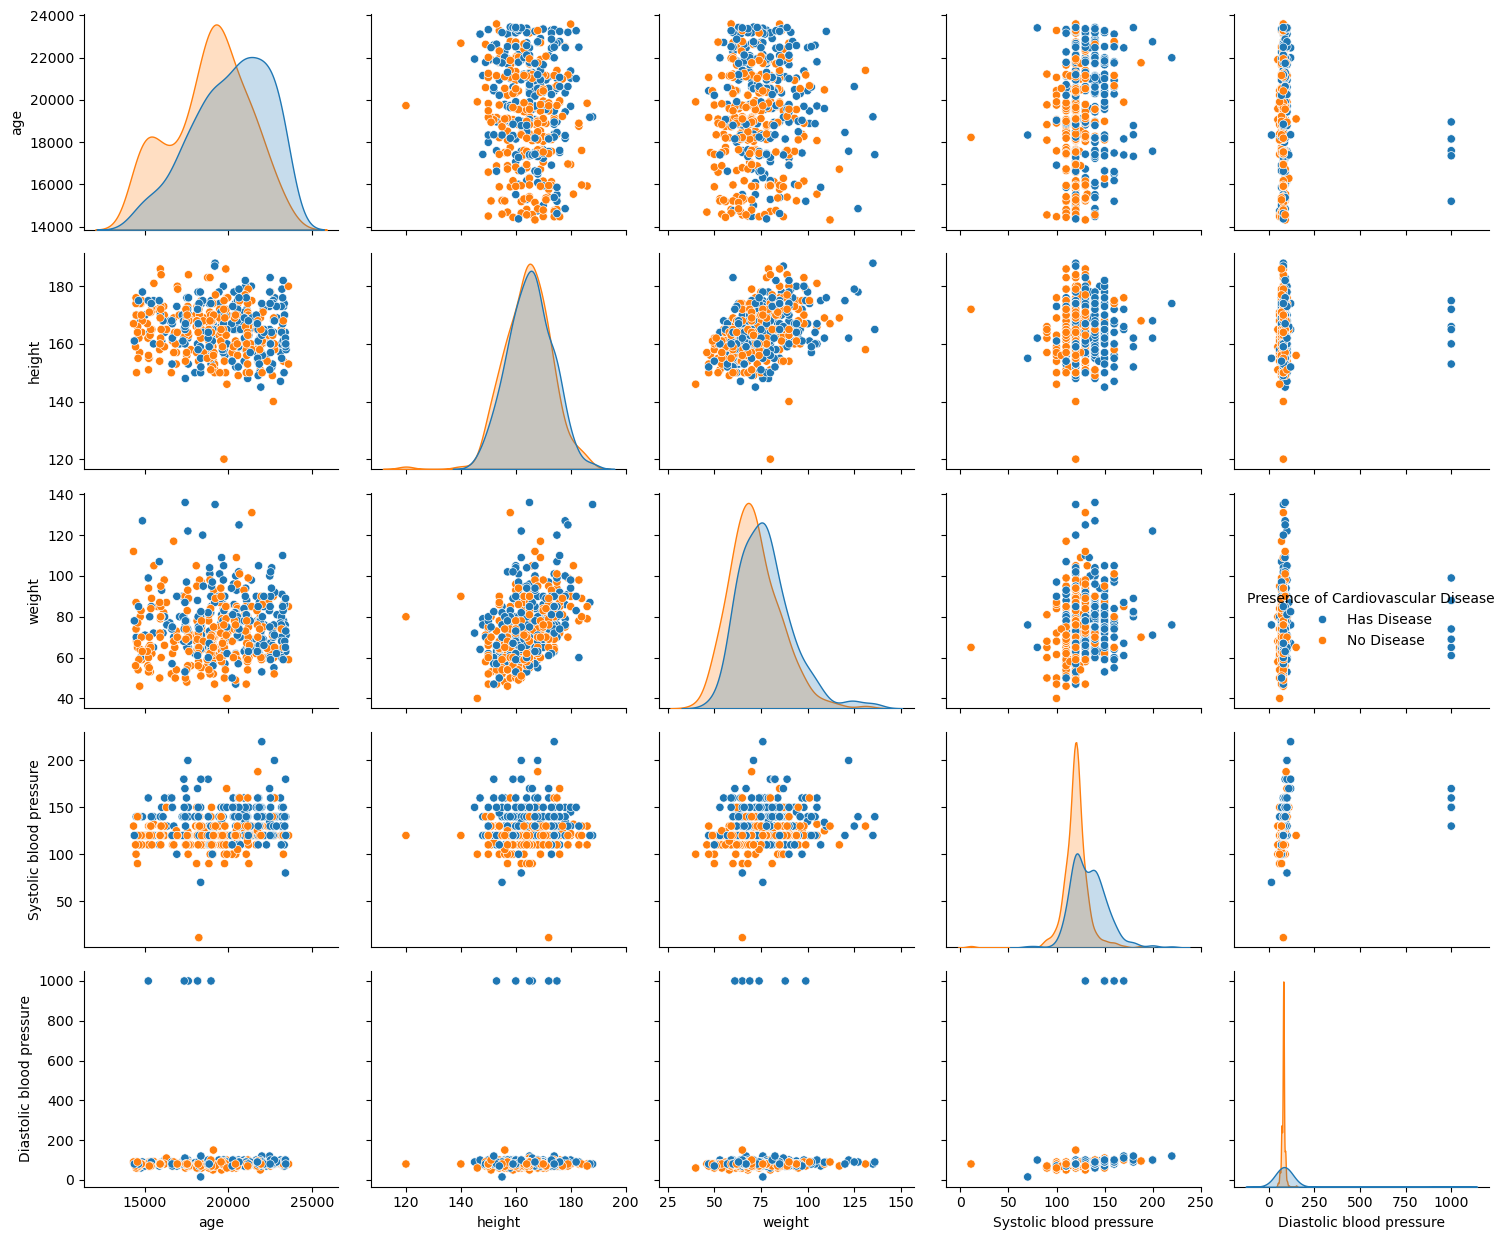

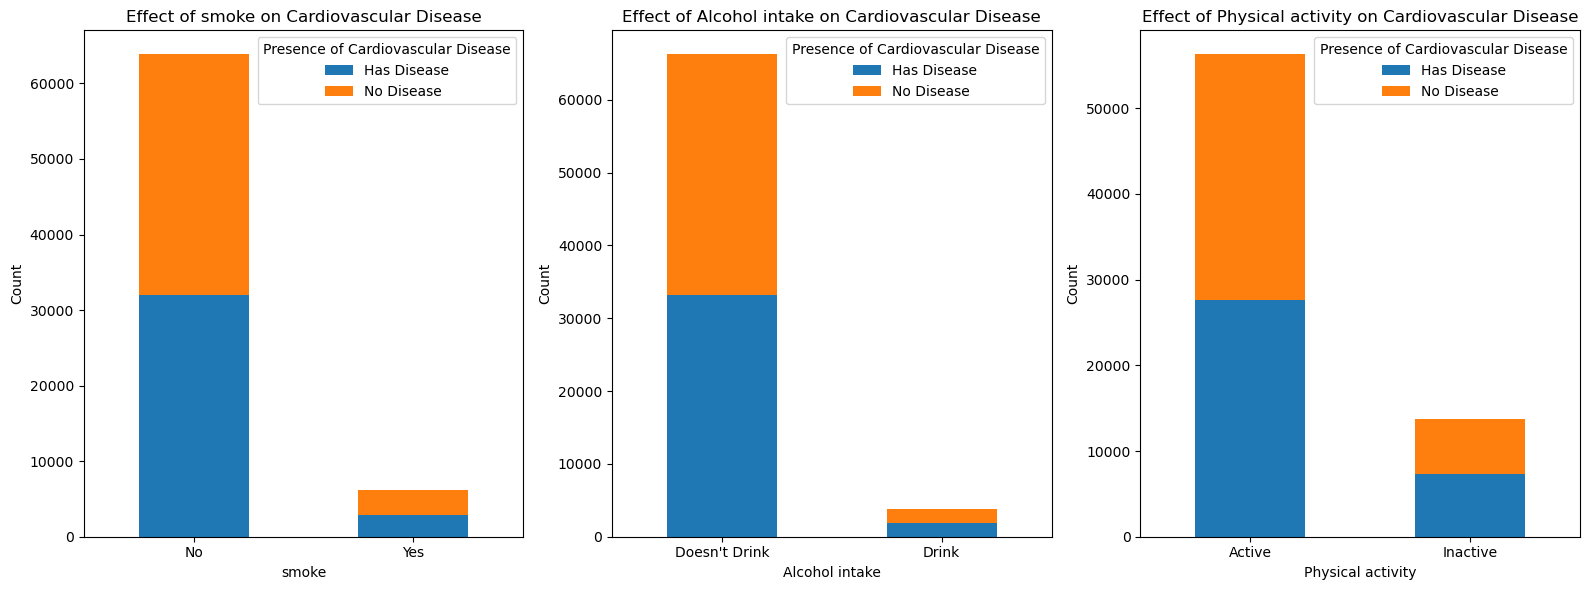

In [17]:
col = ['smoke', 'Alcohol intake', 'Physical activity']

fig, axes = plt.subplots(1, 3, figsize=(16, 6))

for i, feature in enumerate(col):
    grouped = df.groupby([feature, 'Presence of Cardiovascular Disease']).size().unstack()

    ax = axes[i]
    grouped.plot(ax=ax, kind='bar', stacked=True)
    
    ax.set_xlabel(feature)
    ax.set_ylabel('Count')
    ax.set_title(f'Effect of {feature} on Cardiovascular Disease')
    
    handles, labels = ax.get_legend_handles_labels()
    #ax.legend(handles, labels, title='Presence of Cardiovascular Disease', loc='upper right')
    
    ax.set_xticklabels(grouped.index, rotation=0)
    ax.set_xticks(range(len(grouped.index)))

plt.tight_layout()
plt.show()

In [18]:
#convert age to years
df['age'] = df['age'] / 365.25 # i divided by 365.25 in cosideration for leap year
df['age'] = df['age'].astype('int64')

In [19]:
#Calculate age
minAge=min(df.age)
maxAge=max(df.age)
meanAge=df.age.mean()
print("min =",minAge ,"max =", maxAge , "mean =",meanAge)

min = 29 max = 64 mean = 52.80325714285714


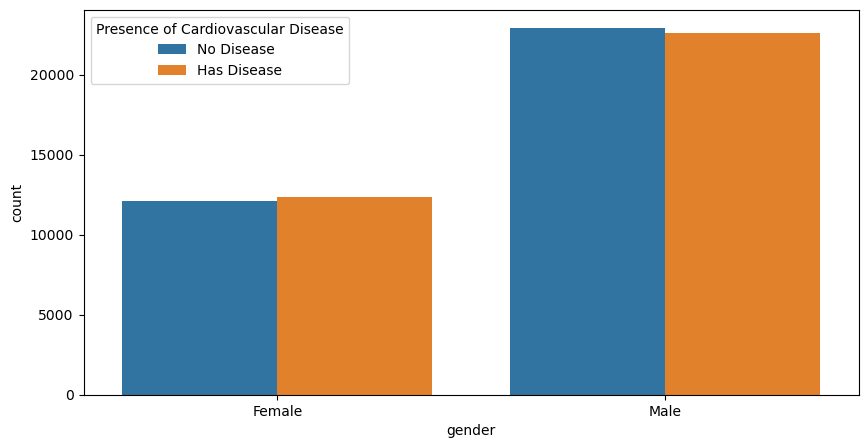

In [20]:
# Visualization of gender with higher cardiovascular disease
plt.figure(figsize=(10,5))
sns.countplot(x='gender', data=df, hue='Presence of Cardiovascular Disease')
plt.show()

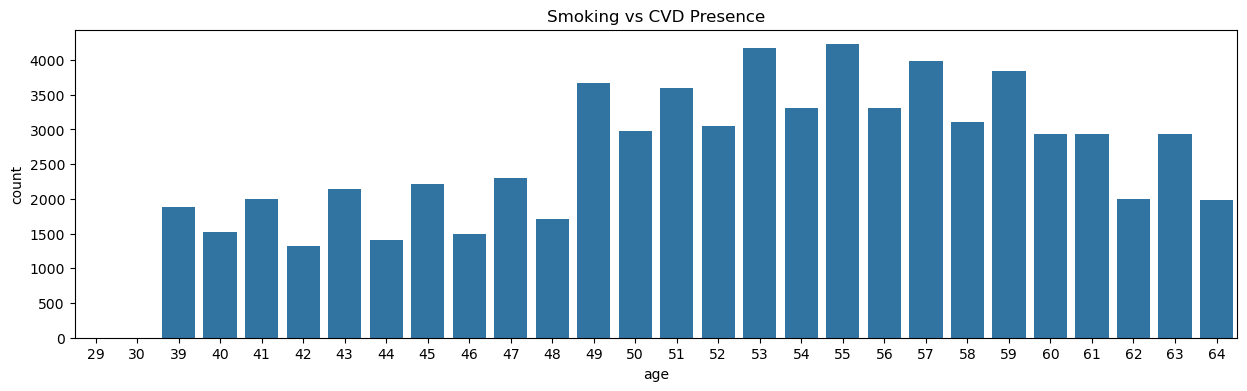

In [21]:
# visulaizing the age range that are mostly likely to develop cardiovascular disease
plt.figure(figsize=(15,4))
sns.countplot(data=df, x='age')
plt.title('Smoking vs CVD Presence')
plt.show()
plt.tight_layout()


In [22]:
# visualizing patients with abnormal bp
# The normal blood pressure range for Systolic Blood Pressure is Less than 120 mmHg while Diastolic Blood Pressure is Less than 80 mmHg
abnormal_bp = df[(df['Systolic blood pressure'] < 90) | (df['Systolic blood pressure'] > 120) |
    (df['Diastolic blood pressure'] < 60) | (df['Diastolic blood pressure'] > 80)
]

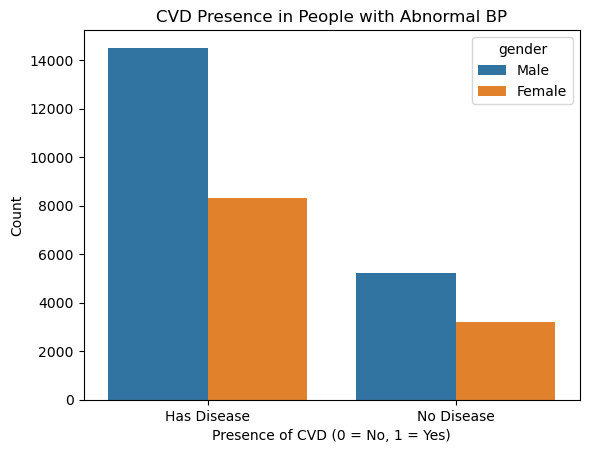

In [23]:
sns.countplot(
    data=abnormal_bp,
    x='Presence of Cardiovascular Disease',
    hue='gender'
)
plt.title('CVD Presence in People with Abnormal BP')
plt.xlabel('Presence of CVD (0 = No, 1 = Yes)')
plt.ylabel('Count')
plt.show()

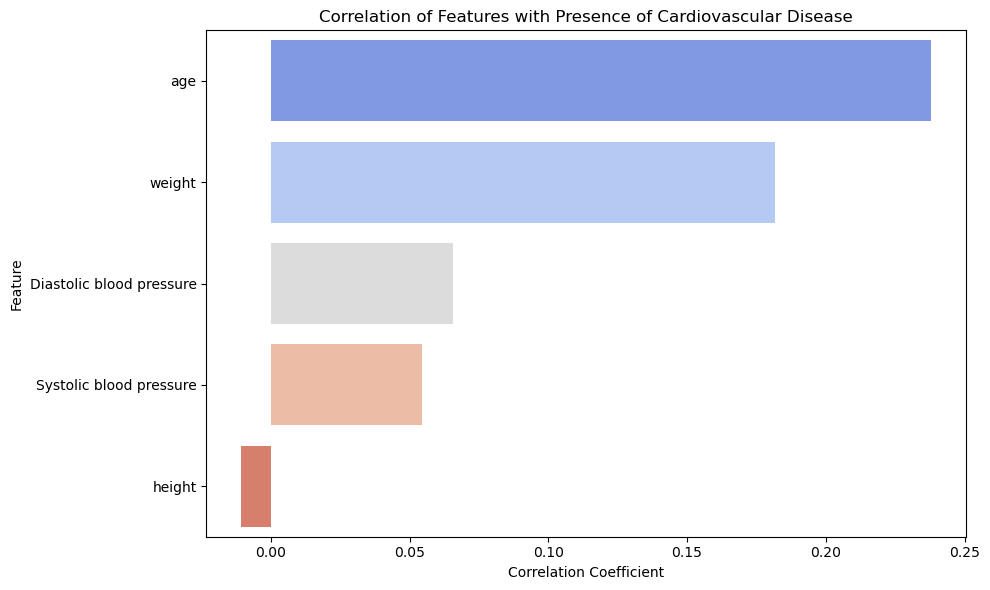

In [24]:
# checking for the features that contributed most to cvd 
df_encoded = df.copy()
df_encoded['Presence of Cardiovascular Disease'] = df_encoded['Presence of Cardiovascular Disease'].replace({'No Disease': 0, 'Has Disease': 1})

# Select only numerical columns
numerical_cols = df_encoded.select_dtypes(include='number')

# Compute correlation with the target
correlation = numerical_cols.corr()['Presence of Cardiovascular Disease'].drop('Presence of Cardiovascular Disease').sort_values(ascending=False)

# Plot
plt.figure(figsize=(10, 6))
sns.barplot(x=correlation.values, y=correlation.index, palette='coolwarm')
plt.title('Correlation of Features with Presence of Cardiovascular Disease')
plt.xlabel('Correlation Coefficient')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()


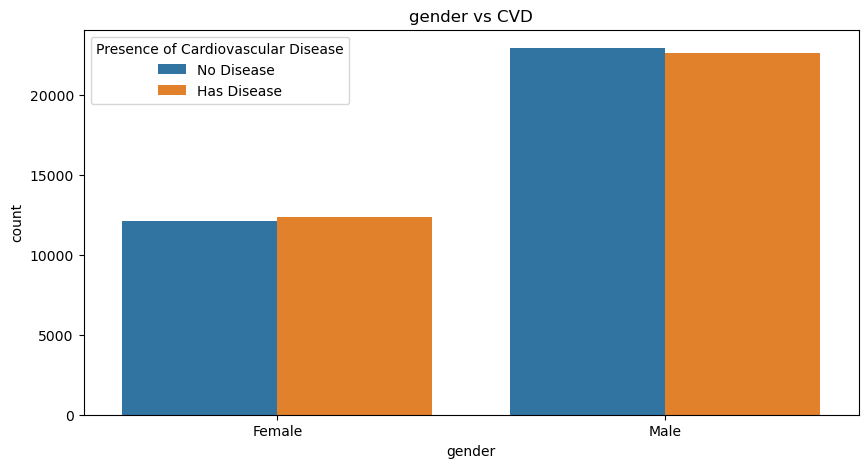

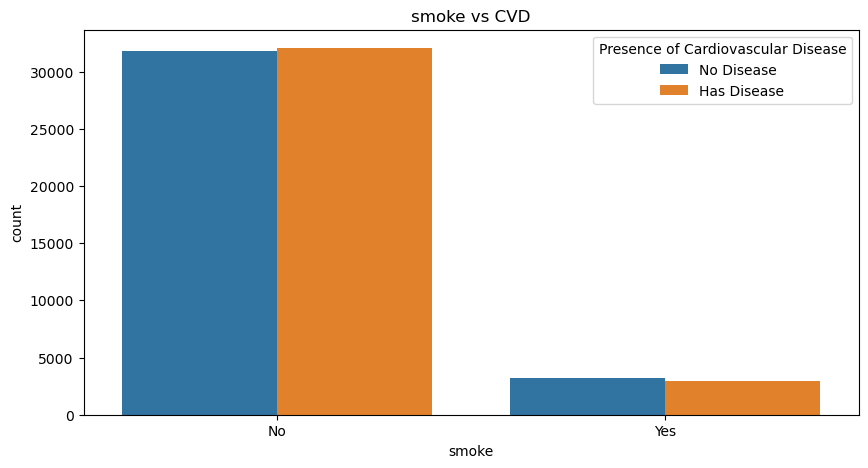

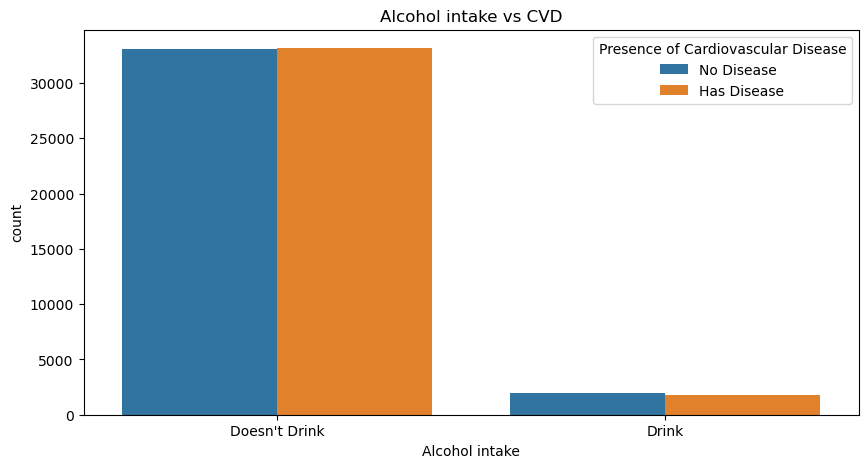

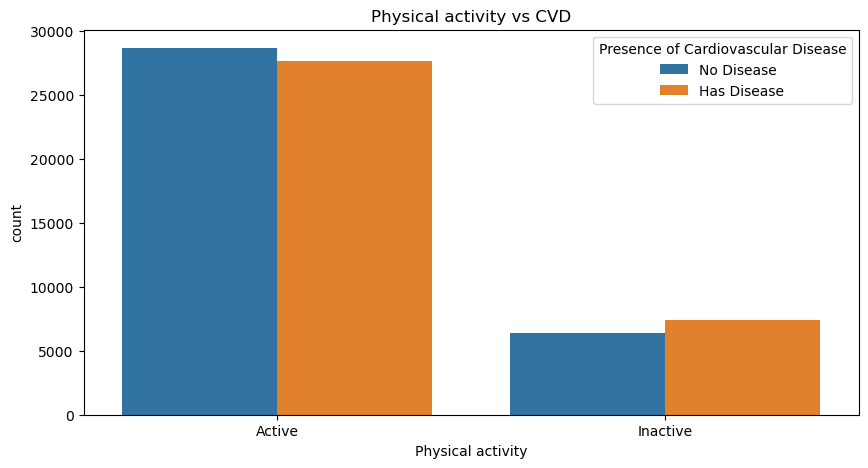

In [25]:
# visualization of all the categorical columns with the target variable
cat_cols = ['gender', 'smoke', 'Alcohol intake', 'Physical activity']
for col in cat_cols:
    plt.figure(figsize=(10,5))
    sns.countplot(x=col, hue='Presence of Cardiovascular Disease', data=df)
    plt.title(f"{col} vs CVD")
    plt.show()


In [26]:
# visualizing whtether lack of physical exercise can contribute to cardiovascular disease
sns.countplot(x='Physical activity', hue='Presence of Cardiovascular Disease', data=df)

<Axes: xlabel='Physical activity', ylabel='count'>

Missing values in each column:
 age                                   0
gender                                0
height                                0
weight                                0
Systolic blood pressure               0
Diastolic blood pressure              0
cholesterol                           0
Glucose Level                         0
smoke                                 0
Alcohol intake                        0
Physical activity                     0
Presence of Cardiovascular Disease    0
dtype: int64


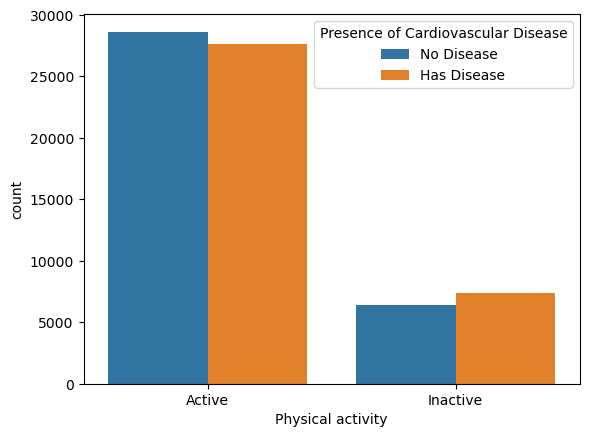

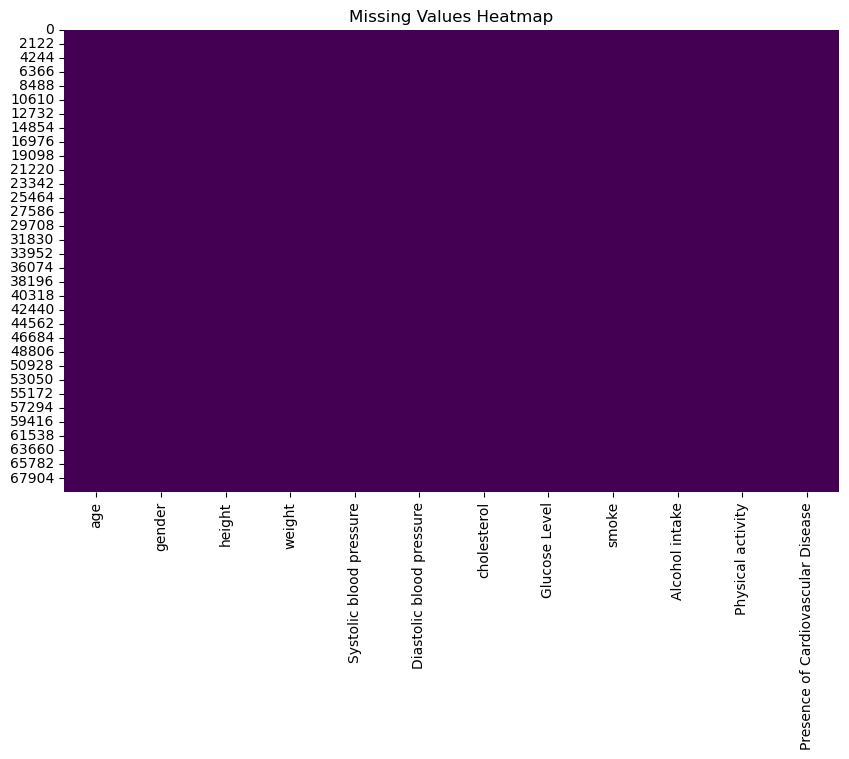

In [27]:
# using an heatmap to  Check for missing values
missing_values = df.isnull().sum()
print("Missing values in each column:\n", missing_values)
plt.figure(figsize=(10, 6))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title("Missing Values Heatmap")
plt.show()


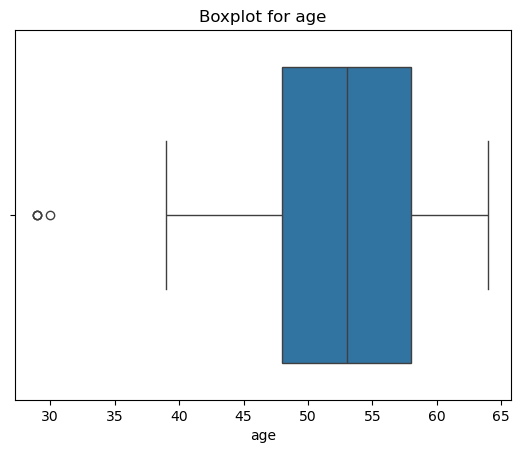

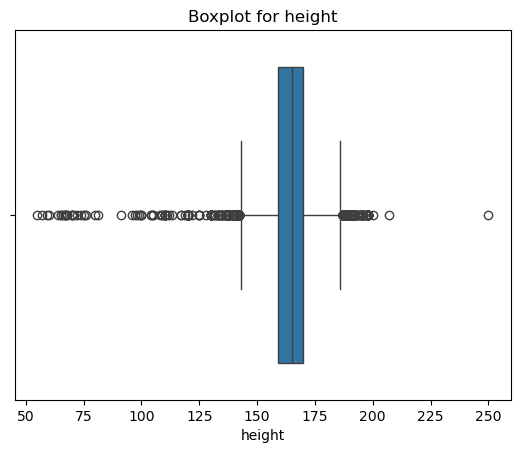

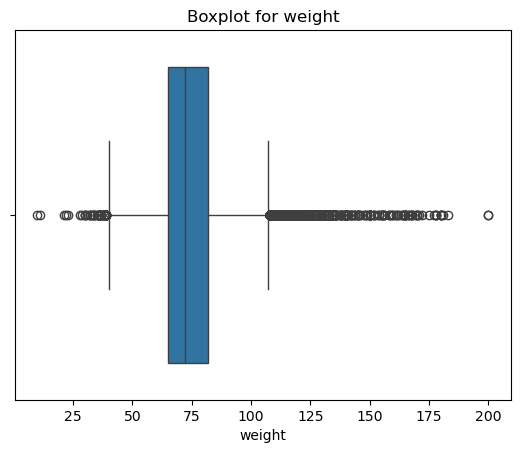

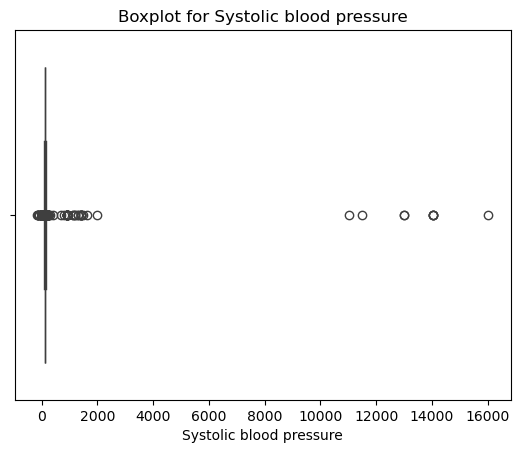

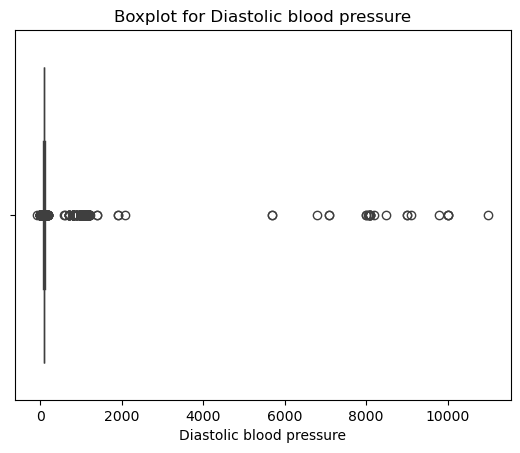

In [28]:
# Boxplot to visualize outliers in the numerical columns
numeric_cols = ['age','height', 'weight', 'Systolic blood pressure', 'Diastolic blood pressure']
for col in numeric_cols:
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot for {col}")
    plt.show()


In [29]:
# Applying Z score to correct the outliers above
from scipy.stats import zscore


numerical_cols = ['Systolic blood pressure', 'Diastolic blood pressure', 'weight', 'height']

# Calculate Z-scores for the numerical columns 
z_scores = df[numerical_cols].apply(zscore)

# Set a threshold for Z-scores (e.g., 3 standard deviations)
threshold = 3

# Remove rows where any of the numerical columns have a Z-score greater than the threshold (outliers)
df_cleaned = df[(np.abs(z_scores) < threshold).all(axis=1)]

# Show cleaned data, retaining the original values
df_cleaned.head(2)

,age,gender,height,weight,Systolic blood pressure,Diastolic blood pressure,cholesterol,Glucose Level,smoke,Alcohol intake,Physical activity,Presence of Cardiovascular Disease
0,50,Female,168,62.0,110,80,Normal,Normal,No,Doesn't Drink,Active,No Disease
1,55,Male,156,85.0,140,90,Well Above Normal,Normal,No,Doesn't Drink,Active,Has Disease


In [30]:
# checking the shape of the cleanded data
df_cleaned.shape

(68071, 12)

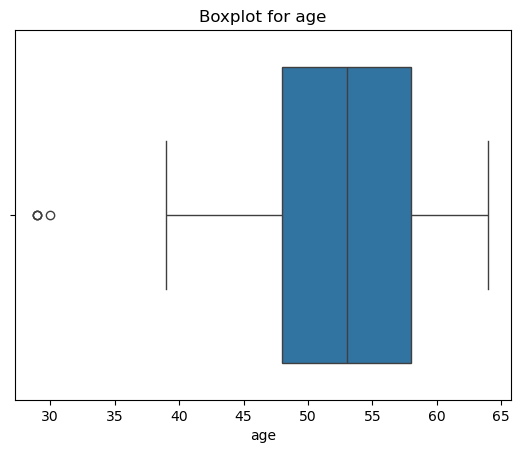

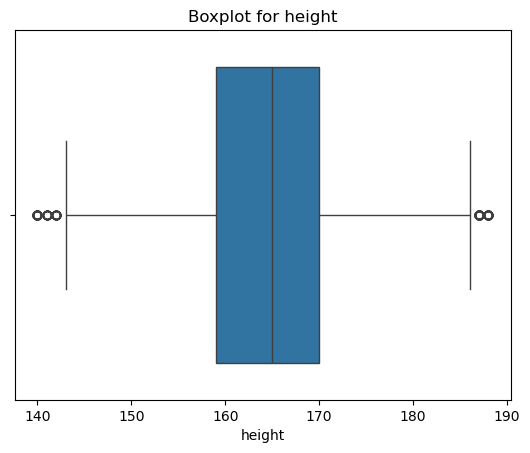

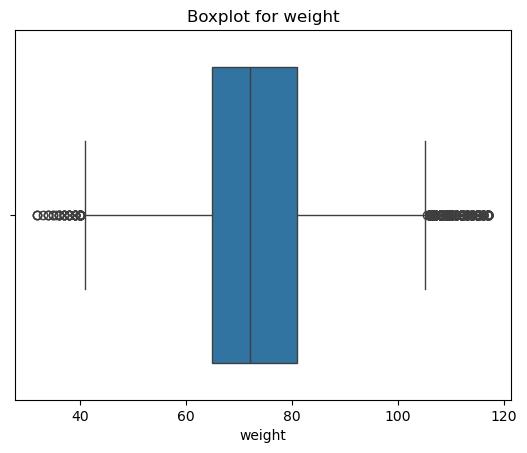

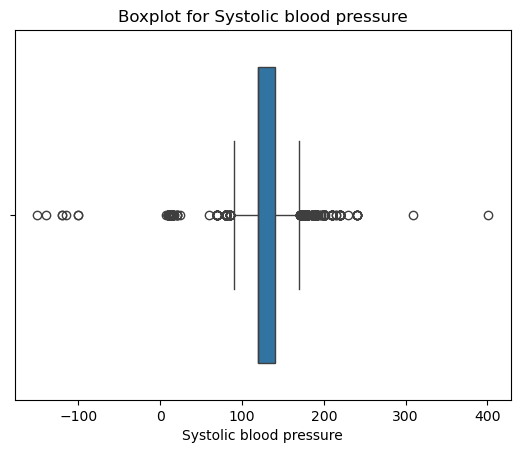

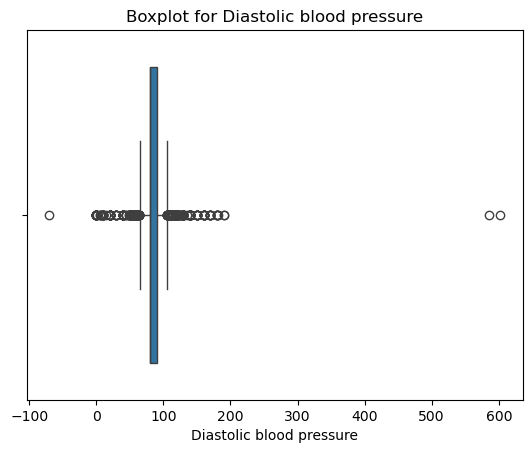

In [31]:
# visualizing the cleaned data after applying z score
numeric_cols = ['age', 'height', 'weight', 'Systolic blood pressure', 'Diastolic blood pressure']
for col in numeric_cols:
    sns.boxplot(x=df_cleaned[col])
    plt.title(f"Boxplot for {col}")
    plt.show()

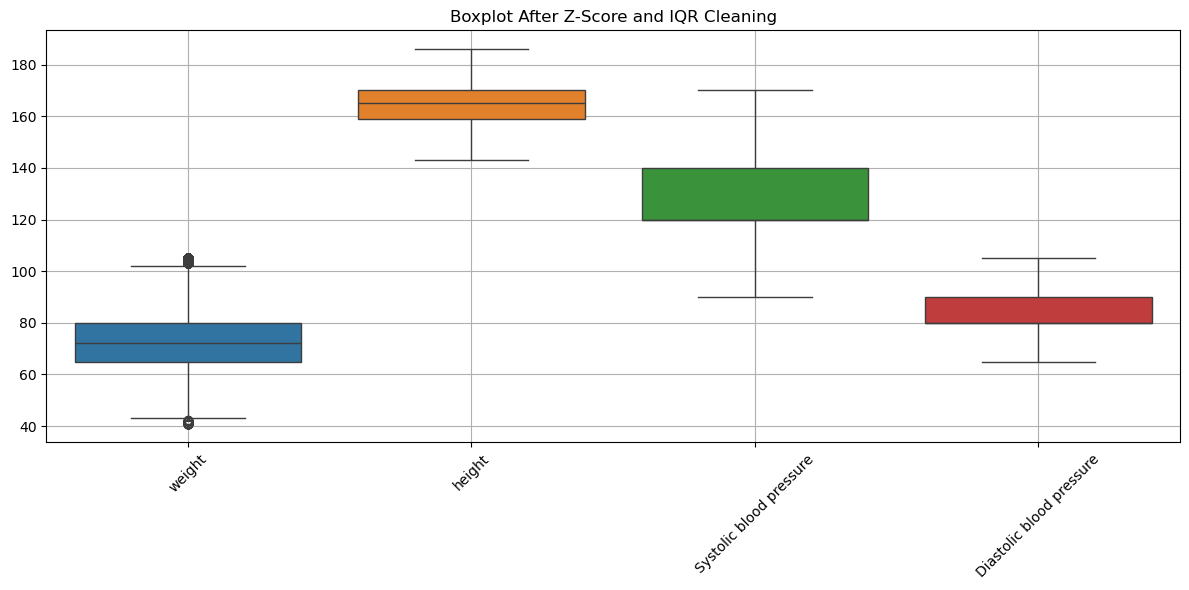

In [32]:
# applying inter quatile range to further cleaned the data
df_iqr_filtered = df_cleaned.copy()

# Define function to apply IQR-based filtering
def remove_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    return df[(df[column] >= lower) & (df[column] <= upper)]

# Apply IQR filtering on top of Z-score cleaning
for col in ['weight', 'height', 'Systolic blood pressure', 'Diastolic blood pressure']:
    df_iqr_filtered = remove_outliers_iqr(df_iqr_filtered, col)

# Visualize the cleaned data
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_iqr_filtered[['weight', 'height', 'Systolic blood pressure', 'Diastolic blood pressure']])
plt.title("Boxplot After Z-Score and IQR Cleaning")
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

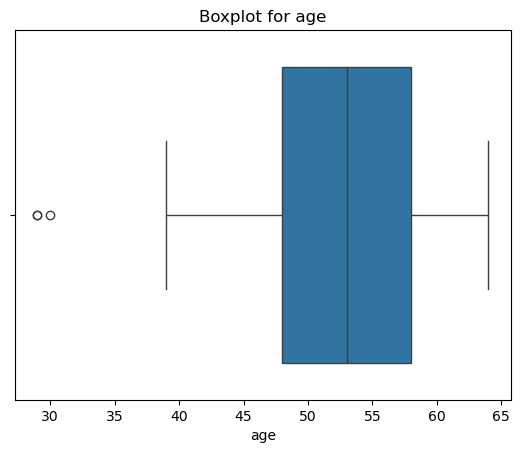

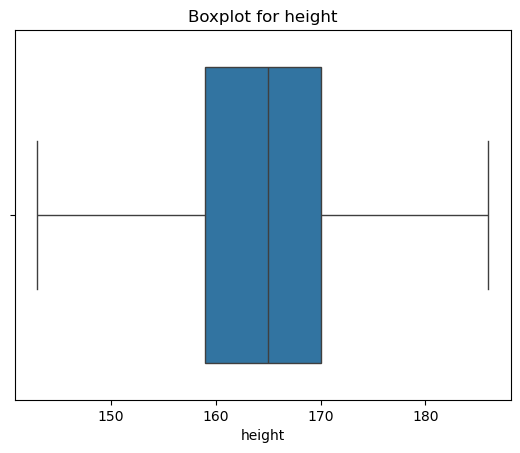

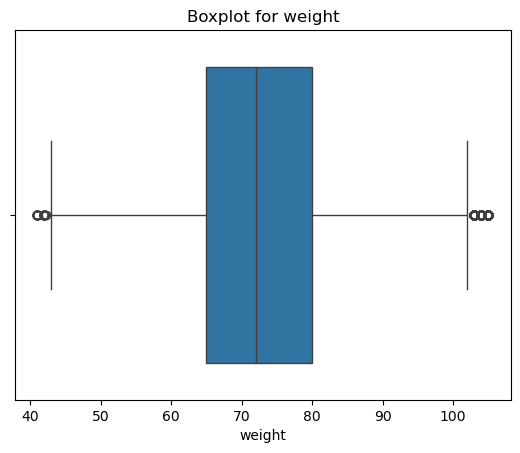

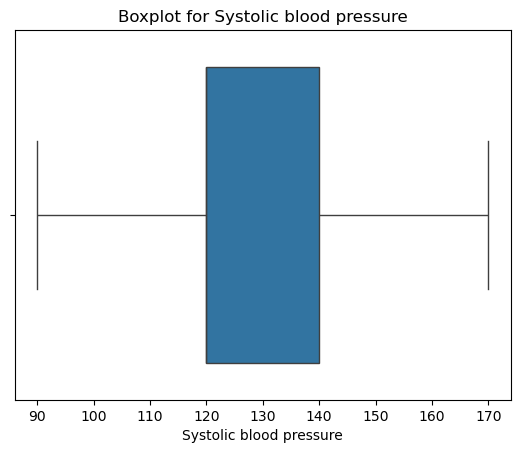

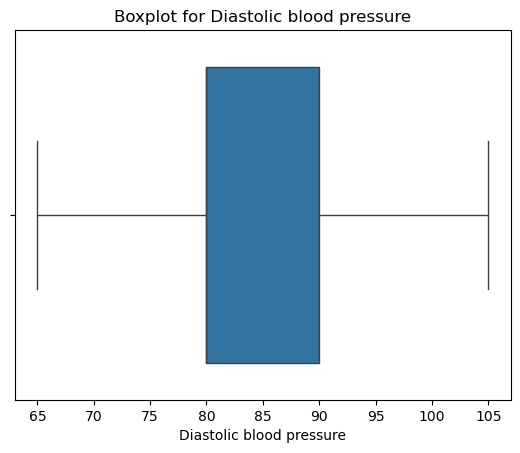

In [33]:
# Boxplot to visualize outliers after applyig IQR
numeric_cols = ['age', 'height', 'weight', 'Systolic blood pressure', 'Diastolic blood pressure']
for col in numeric_cols:
    sns.boxplot(x=df_iqr_filtered[col])
    plt.title(f"Boxplot for {col}")
    plt.show()

In [34]:
# checking the shape of the dataset after applying interquartile Range
df_iqr_filtered.shape

(62242, 12)

# MODELLING

In [35]:
# Importing the required libraries for machine learning
from sklearn.metrics import classification_report,confusion_matrix,accuracy_score,  precision_score, recall_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler

In [37]:
# SCALING AND STANDARDIZING THE NUMERICAL AND CATEGORUCAL COLUMNS AND APPLYING SMOTE TO SETTLE IMBALANCE
from sklearn.preprocessing import LabelEncoder, StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.metrics import classification_report, confusion_matrix

#Encoding the categorical variables
df_encoded = df_iqr_filtered.copy()
categorical_cols = ['gender', 'smoke', 'Alcohol intake', 'Physical activity', 'cholesterol', 'Glucose Level','Presence of Cardiovascular Disease']
labelEncoding = LabelEncoder()

for col in categorical_cols:
    df_encoded[col] = labelEncoding.fit_transform(df_encoded[col])
    
X = df_encoded.drop(columns=['Presence of Cardiovascular Disease'])
y = df_encoded['Presence of Cardiovascular Disease']

#Standardizing the numeric features
numeric_cols = ['age', 'height', 'weight', 'Systolic blood pressure', 'Diastolic blood pressure']
scaler = StandardScaler()
X[numeric_cols] = scaler.fit_transform(X[numeric_cols])

# Step 4: Handle imbalance with SMOTE
#smote = SMOTE(random_state=42)
#X_balanced, y_balanced = smote.fit_resample(X, y)

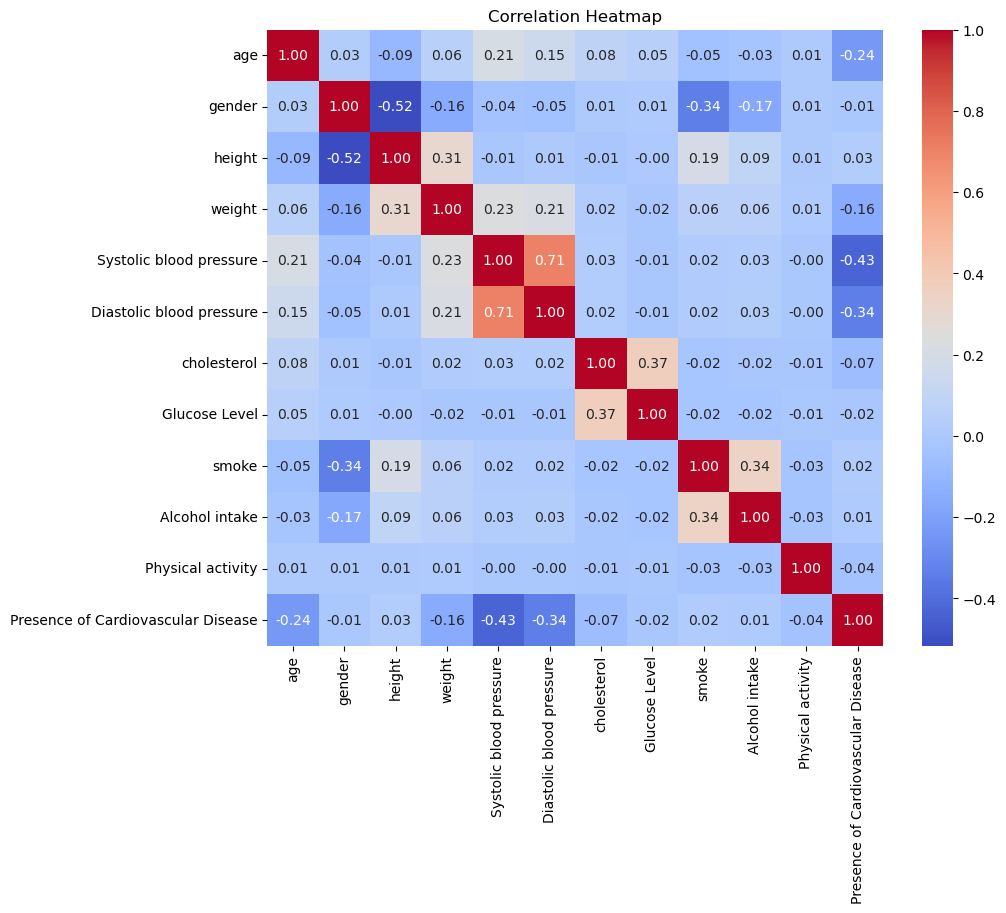

In [38]:
# Correlation matrix to know the correlation of each features with the target variable
plt.figure(figsize=(10, 8))
corr = df_encoded.corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', square=True)
plt.title("Correlation Heatmap")
plt.show()

# MODEL TRAINING

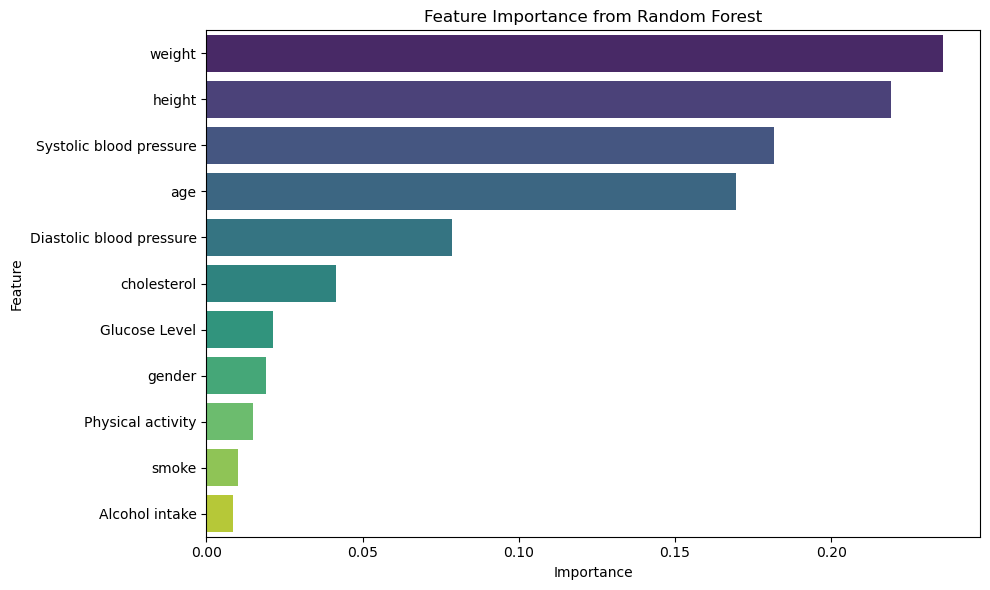

In [39]:
# Train a simple RF model on the encoded data
rf_temp = RandomForestClassifier(random_state=42)
rf_temp.fit(X, y)

#feature importances
importances = rf_temp.feature_importances_
features = X.columns

# Create DataFrame for plotting
feat_imp = pd.DataFrame({'Feature': features, 'Importance': importances})
feat_imp = feat_imp.sort_values(by='Importance', ascending=False)

# Plot
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feat_imp, palette='viridis')
plt.title('Feature Importance from Random Forest')
plt.tight_layout()
plt.show()


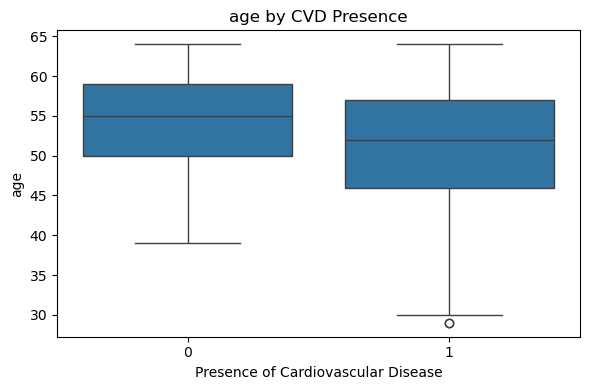

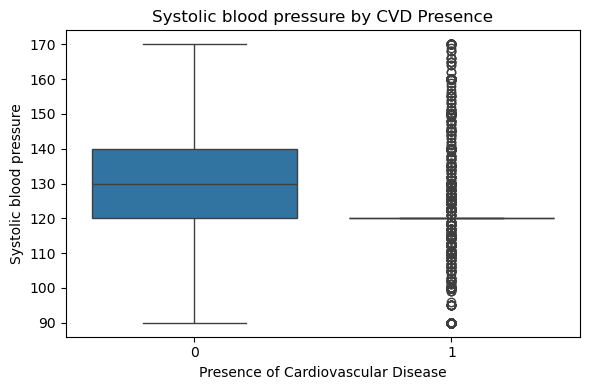

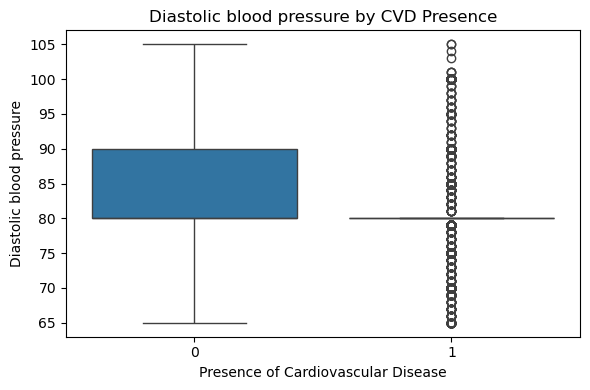

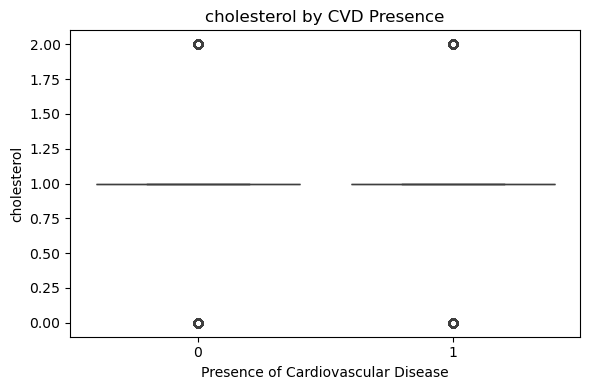

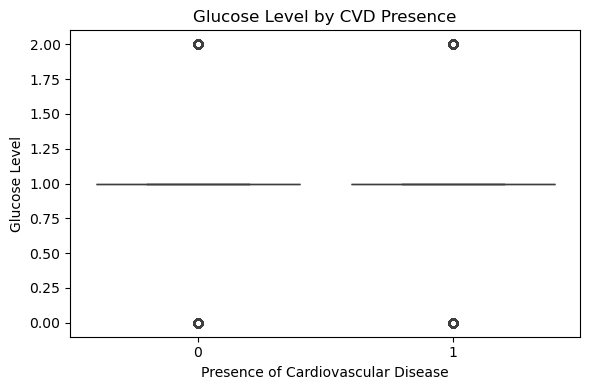

In [40]:
#
key_features = ['age', 'Systolic blood pressure', 'Diastolic blood pressure', 'cholesterol', 'Glucose Level']
for col in key_features:
    plt.figure(figsize=(6, 4))
    sns.boxplot(data=df_encoded, x='Presence of Cardiovascular Disease', y=col)
    plt.title(f'{col} by CVD Presence')
    plt.tight_layout()
    plt.show()


In [41]:
print(df.shape)
print(df_cleaned.shape)
print(df_iqr_filtered.shape)

(70000, 12)
(68071, 12)
(62242, 12)


# MODEL SPLITTING

In [42]:
# MODEL TRAINING
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)
# Step 6: Train models
rf = RandomForestClassifier(max_depth= 10, max_features= 'sqrt', min_samples_split= 5, n_estimators= 200,random_state=42)
rf.fit(X_train, y_train)

RandomForestClassifier(max_depth=10, min_samples_split=5, n_estimators=200,
                       random_state=42)

In [43]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)


KNeighborsClassifier()

# MODEL EVALUATION

In [44]:
# RANDOM FOREST EVALUATION
X_train_prediction = rf.predict(X_train)

rf_trained_data_accuracy = accuracy_score(X_train_prediction,y_train)

print(f" The Accuracy for the random forest trained data is {rf_trained_data_accuracy}")

rf_test_prediction = rf.predict(X_test)

rf_test_data_accuracy = accuracy_score(rf_test_prediction,y_test)

print(f" The Accuracy for the  random forest test data is {rf_test_data_accuracy}")

 The Accuracy for the random forest trained data is 0.7474142951820537
 The Accuracy for the  random forest test data is 0.7342758454494337


In [45]:
# FOR RANDOM FOREST
print("Random Forest Classification Report:\n", classification_report(y_test, rf_test_prediction))


print("Confusion Matrix:\n", confusion_matrix(y_test, rf_test_prediction))

Random Forest Classification Report:
               precision    recall  f1-score   support

           0       0.76      0.68      0.72      6137
           1       0.72      0.79      0.75      6312

    accuracy                           0.73     12449
   macro avg       0.74      0.73      0.73     12449
weighted avg       0.74      0.73      0.73     12449

Confusion Matrix:
 [[4157 1980]
 [1328 4984]]


In [46]:
# KNN EVALUATION
X_train_prediction = knn.predict(X_train)

Knn_training_data_accuracy = accuracy_score(X_train_prediction,y_train)

print(f" The accuracy for the KNN trained data is {Knn_training_data_accuracy}")



knn_test_prediction = knn.predict(X_test)

knn_test_data_accuracy = accuracy_score(knn_test_prediction,y_test)

print(f" The accuracy for the KNN test data is {knn_test_data_accuracy}")

 The accuracy for the KNN trained data is 0.780049404534774
 The accuracy for the KNN test data is 0.6946742710257852


In [47]:
# FOR KNN
print("\nKNN Classification Report:\n", classification_report(y_test,knn_test_prediction))
print("Confusion Matrix:\n", confusion_matrix(y_test, knn_test_prediction))


KNN Classification Report:
               precision    recall  f1-score   support

           0       0.70      0.67      0.68      6137
           1       0.69      0.72      0.70      6312

    accuracy                           0.69     12449
   macro avg       0.69      0.69      0.69     12449
weighted avg       0.69      0.69      0.69     12449

Confusion Matrix:
 [[4131 2006]
 [1795 4517]]


In [ ]:
data = [
    {
        "ML Model": "Random Forest Classifier",
        "Accuracy": 0.974,
        "f1_score": 0.977,
        "Recall": 0.994,
        "Precision": 0.986,
    },
    {
        "ML Model": "KNN Classifier",
        "Accuracy": 0.970,
        "f1_score": 0.973,
        "Recall": 0.993,
        "Precision": 0.984,
    }
]

# Create DataFrame
df_metrics = pd.DataFrame(data)

# Print in console
print(df_metrics)

# MAKING A PRIDICTIVE SYSTEM


In [ ]:
input_data = (50,0,168,62.0,110,80,1,1,0,0,0)


# changing the input data into numpy array
input_data_as_numpy_array = np.asarray(input_data)
# reshaping the array because we are predicting for one instance

input_data_reshaped = input_data_as_numpy_array.reshape(1,-1)
prediction = rf.predict(input_data_reshaped)

prediction

if (prediction[0] == 0):
    print("The person is has a High risk of developing cardiovascular disease")
else:
    print("The person is has a low risk of developing cardiovascular disease")

In [ ]:
import pickle as pickle
# saving the file
filename = "Cardiovascular_trained_model.sav"
#saving the model
pickle.dump(rf, open(filename, "wb"))


In [ ]:
#loading the save model
loaded_model = pickle.load(open("Cardiovascular_trained_model.sav", "rb"))

In [ ]:
input_data = (50,0,168,62.0,110,80,1,1,0,0,0)


# changing the input data into numpy array
input_data_as_numpy_array = np.asarray(input_data)
# reshaping the array because we are predicting for one instance

input_data_reshaped = input_data_as_numpy_array.reshape(1,-1)
prediction = loaded_model.predict(input_data_reshaped)

prediction

if (prediction[0] == 0):
    print("The person is has a High risk of developing cardiovascular disease")
else:
    print("The person is has a low risk of developing cardiovascular disease")

In [ ]:
'''
Normal Ranges for Each Feature
Feature	Normal Range / Ideal Value	Notes
Age	Varies (CVD risk rises > 45 for men, > 55 for women)	No fixed “normal” — risk increases with age
Height (cm)	Depends on gender/population (160–190 cm typical)	Used mainly for BMI
Weight (kg)	Depends on height/BMI (50–100 kg common)	BMI = weight / height²
Systolic Blood Pressure (SBP)	90–119 mmHg	120–129 = elevated, ≥130 = hypertension
Diastolic Blood Pressure (DBP)	60–79 mmHg	80–89 = Stage 1 hypertension
Cholesterol Level	Normal = 1 (in your dataset)	1 = Normal, 2 = Above Normal, 3 = Well Above
Glucose Level	Normal = 1 (in your dataset)	Same encoding as cholesterol
Smoking Status	0 = Non-smoker	1 = Smoker
Alcohol Intake	0 = Does not drink	1 = Drinks regularly
Physical Activity	1 = Active	0 = Not active
Gender	1 = Male, 0 = Female	Binary encoding